# Derin Öğrenme Ödev 2 - Görüntü Sınıflandırma (CNN)

İsa Mirza Sincap - 23120205033

Telefonumla 5 nesnenin fotoğrafını çektim: kalem, saat, sepet, tavuk ve yastık. Bu 5 sınıfı tanıyan bir model eğitmek için Open Images V7 veri setinden bu sınıflara ait görüntüleri indirdim. ImageNet'te önceden eğitilmiş ResNet50'yi transfer learning ile bu 5 sınıfa uyarladım. En sonda modeli Gradio ile küçük bir uygulamaya çevirdim ve kendi fotoğraflarımla test ettim.

Colab'da GPU (T4) ile çalıştırdım. Kendi fotoğraflarım `fotograflar/` klasöründe, Colab'da dosyalar kısmına bu klasörü yükledim.

In [1]:
!pip -q install gradio

In [2]:
import os, csv, time, random, urllib.request
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from PIL import Image, ImageOps

keras.utils.set_random_seed(33)
BOYUT = 224
BATCH = 32
EPOCH_1 = 10
EPOCH_2 = 6
print(tf.__version__, tf.config.list_physical_devices("GPU"))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Veri seti

Open Images V7 (Google, CC BY 4.0): https://storage.googleapis.com/openimages/web/index.html

Open Images'ta her görüntü için insanların doğruladığı etiketler var (image-level labels). Train bölümünün etiket dosyası 2.7 GB olduğu için sadece validation ve test bölümlerinin etiketlerini kullandım (toplam ~120 MB). Bu iki bölümde 5 sınıfım için yeterli görüntü vardı.

Sınıfları Open Images etiketlerine şöyle eşledim:
- kalem: Pen, Fountain pen
- saat: Watch
- sepet: Basket, Laundry basket, Storage basket, Picnic basket
- tavuk: Chicken
- yastik: Pillow, Cushion

Sadece etiketi "var" (Confidence = 1) olan ve 5 sınıfımdan yalnızca birini içeren görüntüleri aldım. Yoksa aynı fotoğrafta hem yastık hem sepet olunca etiket belirsiz oluyor.

In [3]:
SINIFLAR = {
    "kalem": ["/m/0k1tl", "/m/0gd6f"],
    "saat": ["/m/0gjkl"],
    "sepet": ["/m/01z562", "/m/0h8ntmx", "/m/0h8nt_x", "/m/07kng9"],
    "tavuk": ["/m/09b5t"],
    "yastik": ["/m/034c16", "/m/0174g1"],
}
etiket_sinif = {e: s for s, liste in SINIFLAR.items() for e in liste}

goruntu_siniflari = {}
for bolum, dosya in [("validation", "val"), ("test", "test")]:
    yol = f"{dosya}.csv"
    if not os.path.exists(yol):
        urllib.request.urlretrieve(
            f"https://storage.googleapis.com/openimages/v7/oidv7-{dosya}-annotations-human-imagelabels.csv", yol)
    for satir in csv.DictReader(open(yol)):
        if satir["LabelName"] in etiket_sinif and satir["Confidence"] == "1":
            goruntu_siniflari.setdefault((bolum, satir["ImageID"]), set()).add(etiket_sinif[satir["LabelName"]])

ornekler = [(bolum, gid, s.pop()) for (bolum, gid), s in goruntu_siniflari.items() if len(s) == 1]
ornekler.sort()
for s in SINIFLAR:
    print(s, sum(1 for o in ornekler if o[2] == s))
print("toplam:", len(ornekler))

kalem 180
saat 154
sepet 399
tavuk 261
yastik 520
toplam: 1514


Veriyi %70 train, %15 validation, %15 test olarak ayırdım (stratify ile, her sınıftan aynı oranda). Görüntüleri indirirken kısa kenarı 256 piksel olacak şekilde küçülttüm, yoksa bazıları birkaç MB.

In [4]:
etiketler = [o[2] for o in ornekler]
train, gecici = train_test_split(ornekler, test_size=0.3, stratify=etiketler, random_state=33)
val, test = train_test_split(gecici, test_size=0.5, stratify=[o[2] for o in gecici], random_state=33)
print("train:", len(train), "validation:", len(val), "test:", len(test))

def indir(is_):
    kume, (bolum, gid, sinif) = is_
    hedef = f"veri/{kume}/{sinif}/{gid}.jpg"
    if os.path.exists(hedef):
        return True
    try:
        veri = urllib.request.urlopen(f"https://open-images-dataset.s3.amazonaws.com/{bolum}/{gid}.jpg", timeout=30).read()
        img = Image.open(BytesIO(veri)).convert("RGB")
        oran = 256 / min(img.size)
        img = img.resize((round(img.width * oran), round(img.height * oran)))
        os.makedirs(os.path.dirname(hedef), exist_ok=True)
        img.save(hedef, quality=90)
        return True
    except Exception:
        return False

isler = [("train", o) for o in train] + [("val", o) for o in val] + [("test", o) for o in test]
baslangic = time.time()
with ThreadPoolExecutor(32) as havuz:
    sonuc = list(havuz.map(indir, isler))
print("indirilen:", sum(sonuc), "/", len(isler), "-", round(time.time() - baslangic), "sn")

train: 1059 validation: 227 test: 228
indirilen: 1514 / 1514 - 0 sn


In [5]:
def veri_yukle(kume, karistir):
    return keras.utils.image_dataset_from_directory(
        f"veri/{kume}", label_mode="categorical", image_size=(BOYUT, BOYUT),
        crop_to_aspect_ratio=True, batch_size=BATCH, shuffle=karistir, seed=33)

train_ds = veri_yukle("train", True)
val_ds = veri_yukle("val", False)
test_ds = veri_yukle("test", False)
sinif_adlari = train_ds.class_names
print(sinif_adlari)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

Found 1059 files belonging to 5 classes.
Found 227 files belonging to 5 classes.
Found 228 files belonging to 5 classes.
['kalem', 'saat', 'sepet', 'tavuk', 'yastik']


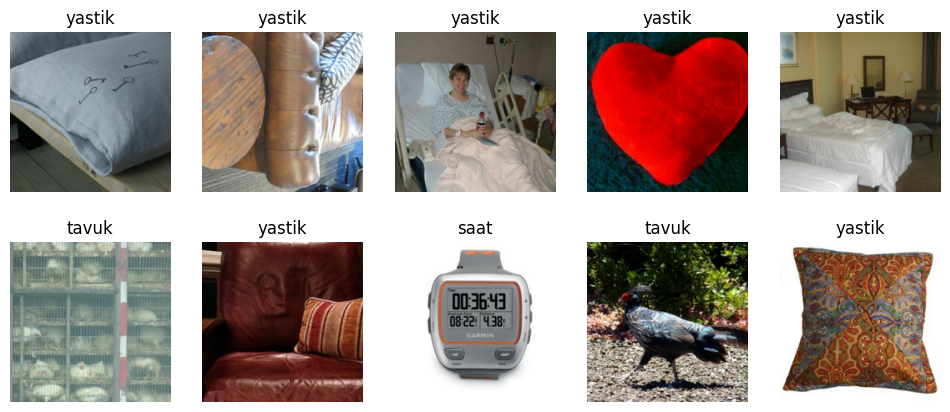

In [6]:
plt.figure(figsize=(12, 5))
x, y = next(iter(train_ds))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(sinif_adlari[y[i].numpy().argmax()])
    plt.axis("off")
plt.show()

Sınıflar dengeli değil (yastık en çok, saat en az). Az olan sınıfların loss'a etkisi artsın diye class weight kullandım: her sınıfın ağırlığı toplam / (5 * o sınıfın sayısı).

In [7]:
sayilar = {s: len(os.listdir(f"veri/train/{s}")) for s in sinif_adlari}
toplam = sum(sayilar.values())
class_weight = {i: toplam / (len(sinif_adlari) * sayilar[s]) for i, s in enumerate(sinif_adlari)}
print(sayilar)
print({s: round(class_weight[i], 2) for i, s in enumerate(sinif_adlari)})

{'kalem': 126, 'saat': 108, 'sepet': 279, 'tavuk': 182, 'yastik': 364}
{'kalem': 1.68, 'saat': 1.96, 'sepet': 0.76, 'tavuk': 1.16, 'yastik': 0.58}


## Model

Elimde sınıf başına birkaç yüz görüntü var, sıfırdan bir CNN eğitmek için bu az. O yüzden ImageNet'te eğitilmiş ResNet50'yi kullandım (transfer learning):
- ResNet50'nin sınıflandırma katmanını çıkardım, sadece konvolüsyon kısmını aldım
- üstüne GlobalAveragePooling + Dropout(0.3) + 5 nöronlu Dense ekledim
- çıkış aktivasyonu softmax (5 sınıftan birini seçiyor, olasılıklar toplamı 1)
- loss: categorical crossentropy (etiketler one-hot)
- veri artırma: yatay çevirme, ±%10 döndürme, ±%10 zoom (sadece eğitimde çalışıyor)
- girdi boyutu 224x224x3, ResNet50'nin ImageNet'te eğitildiği boyut

Eğitimi iki aşamada yaptım:
1. ResNet50 donuk, sadece benim eklediğim katmanlar eğitiliyor. Adam, lr = 0.001, en fazla 10 epoch.
2. ResNet50'nin son bloğunu (conv5) açıp çok küçük lr ile ince ayar. Adam, lr = 0.00001, 6 epoch. lr büyük olursa önceden öğrenilmiş ağırlıklar bozuluyor.

Batch size 32. Adam'ı seçtim çünkü lr'yi çok ayarlamadan hızlı yakınsıyor. Validation loss 3 epoch iyileşmezse durdurup en iyi ağırlıklara dönüyorum (early stopping).

In [8]:
taban = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(BOYUT, BOYUT, 3))
taban.trainable = False

veri_artirma = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

girdi = keras.Input((BOYUT, BOYUT, 3))
x = veri_artirma(girdi)
x = keras.applications.resnet50.preprocess_input(x)
x = taban(x, training=False)  # BatchNorm katmanları ince ayarda da inference modunda kalsın
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
cikti = layers.Dense(len(sinif_adlari), activation="softmax")(x)
model = keras.Model(girdi, cikti)

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 5)         │     10,245 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [9]:
erken_dur = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

baslangic = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCH_1, class_weight=class_weight,
               callbacks=[erken_dur], verbose=2)
sure_1 = time.time() - baslangic
print("1. aşama süresi:", round(sure_1, 1), "sn")

Epoch 1/10
34/34 - 22s - 641ms/step - accuracy: 0.6402 - loss: 1.0539 - val_accuracy: 0.8590 - val_loss: 0.4416
Epoch 2/10
34/34 - 6s - 162ms/step - accuracy: 0.8215 - loss: 0.5421 - val_accuracy: 0.8722 - val_loss: 0.3643
Epoch 3/10
34/34 - 6s - 189ms/step - accuracy: 0.8659 - loss: 0.4058 - val_accuracy: 0.8767 - val_loss: 0.3340
Epoch 4/10
34/34 - 6s - 164ms/step - accuracy: 0.8791 - loss: 0.3479 - val_accuracy: 0.8767 - val_loss: 0.3277
Epoch 5/10
34/34 - 6s - 170ms/step - accuracy: 0.8914 - loss: 0.2833 - val_accuracy: 0.8722 - val_loss: 0.3266
Epoch 6/10
34/34 - 6s - 166ms/step - accuracy: 0.9131 - loss: 0.2582 - val_accuracy: 0.8678 - val_loss: 0.3244
Epoch 7/10
34/34 - 6s - 166ms/step - accuracy: 0.9037 - loss: 0.2430 - val_accuracy: 0.8767 - val_loss: 0.3265
Epoch 8/10
34/34 - 6s - 173ms/step - accuracy: 0.9197 - loss: 0.2057 - val_accuracy: 0.8767 - val_loss: 0.3243
Epoch 9/10
34/34 - 6s - 169ms/step - accuracy: 0.9254 - loss: 0.1833 - val_accuracy: 0.8943 - val_loss: 0.3484


In [10]:
taban.trainable = True
for katman in taban.layers:
    katman.trainable = katman.name.startswith("conv5")

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])

# yeni fit için yeni callback, eskisi 1. aşamanın en iyi loss değerini hatırlıyor
erken_dur = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

baslangic = time.time()
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCH_2, class_weight=class_weight,
               callbacks=[erken_dur], verbose=2)
sure_2 = time.time() - baslangic
egitim_suresi = sure_1 + sure_2
print("2. aşama süresi:", round(sure_2, 1), "sn")
print("Toplam eğitim süresi:", round(egitim_suresi, 1), "sn")

Epoch 1/6
34/34 - 25s - 724ms/step - accuracy: 0.8886 - loss: 0.2452 - val_accuracy: 0.8678 - val_loss: 0.3206
Epoch 2/6
34/34 - 8s - 238ms/step - accuracy: 0.9160 - loss: 0.1955 - val_accuracy: 0.8722 - val_loss: 0.3188
Epoch 3/6
34/34 - 8s - 240ms/step - accuracy: 0.9320 - loss: 0.1718 - val_accuracy: 0.8722 - val_loss: 0.3195
Epoch 4/6
34/34 - 8s - 237ms/step - accuracy: 0.9415 - loss: 0.1482 - val_accuracy: 0.8722 - val_loss: 0.3201
Epoch 5/6
34/34 - 8s - 227ms/step - accuracy: 0.9452 - loss: 0.1365 - val_accuracy: 0.8811 - val_loss: 0.3192
2. aşama süresi: 56.9 sn
Toplam eğitim süresi: 131.3 sn


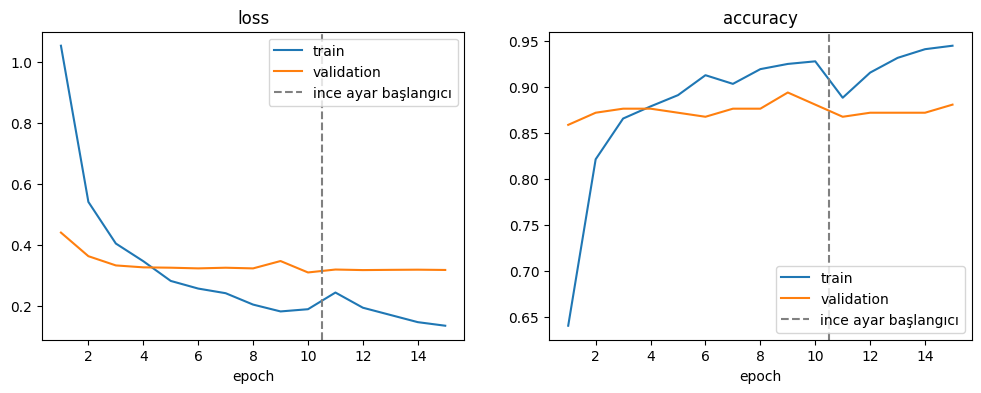

In [11]:
gecmis = {k: h1.history[k] + h2.history[k] for k in h1.history}
epochlar = range(1, len(gecmis["loss"]) + 1)
ayrim = len(h1.history["loss"]) + 0.5

plt.figure(figsize=(12, 4))
for i, metrik in enumerate(["loss", "accuracy"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(epochlar, gecmis[metrik], label="train")
    plt.plot(epochlar, gecmis["val_" + metrik], label="validation")
    plt.axvline(ayrim, color="gray", linestyle="--", label="ince ayar başlangıcı")
    plt.title(metrik)
    plt.xlabel("epoch")
    plt.legend()
plt.show()

## Test sonuçları

Test setini sadece burada kullandım. Sınıflandırma için accuracy, precision, recall ve F1-score'a baktım. Sınıflar dengesiz olduğu için macro ortalamayı da yazdırdım.

Test accuracy: 0.8728
              precision    recall  f1-score   support

       kalem      0.786     0.815     0.800        27
        saat      0.792     0.826     0.809        23
       sepet      0.873     0.800     0.835        60
       tavuk      0.949     0.925     0.937        40
      yastik      0.890     0.936     0.912        78

    accuracy                          0.873       228
   macro avg      0.858     0.860     0.859       228
weighted avg      0.874     0.873     0.872       228



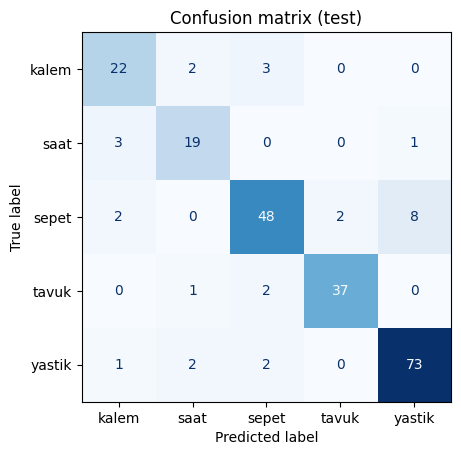

In [12]:
y_gercek = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_ds])

baslangic = time.time()
olasiliklar = model.predict(test_ds, verbose=0)
toplu_sure = time.time() - baslangic
y_tahmin = olasiliklar.argmax(axis=1)

print("Test accuracy:", round(accuracy_score(y_gercek, y_tahmin), 4))
print(classification_report(y_gercek, y_tahmin, target_names=sinif_adlari, digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_gercek, y_tahmin), display_labels=sinif_adlari).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test)")
plt.show()

Tahmin süresini iki şekilde ölçtüm: test setinin tamamını toplu verince görüntü başına süre, bir de uygulamadaki gibi tek tek görüntü verince süre (ilk 5 çağrıyı ısınma için saymadım, sonraki 20 çağrının medyanını aldım).

In [13]:
tek = next(iter(test_ds))[0][:1]
for _ in range(5):
    model(tek, training=False)
sureler = []
for _ in range(20):
    t = time.time()
    model(tek, training=False)
    sureler.append(time.time() - t)

print("Toplu tahminde görüntü başına:", round(1000 * toplu_sure / len(y_gercek), 2), "ms")
print("Tek görüntü tahmini:", round(1000 * np.median(sureler), 2), "ms")

Toplu tahminde görüntü başına: 28.27 ms
Tek görüntü tahmini: 228.04 ms


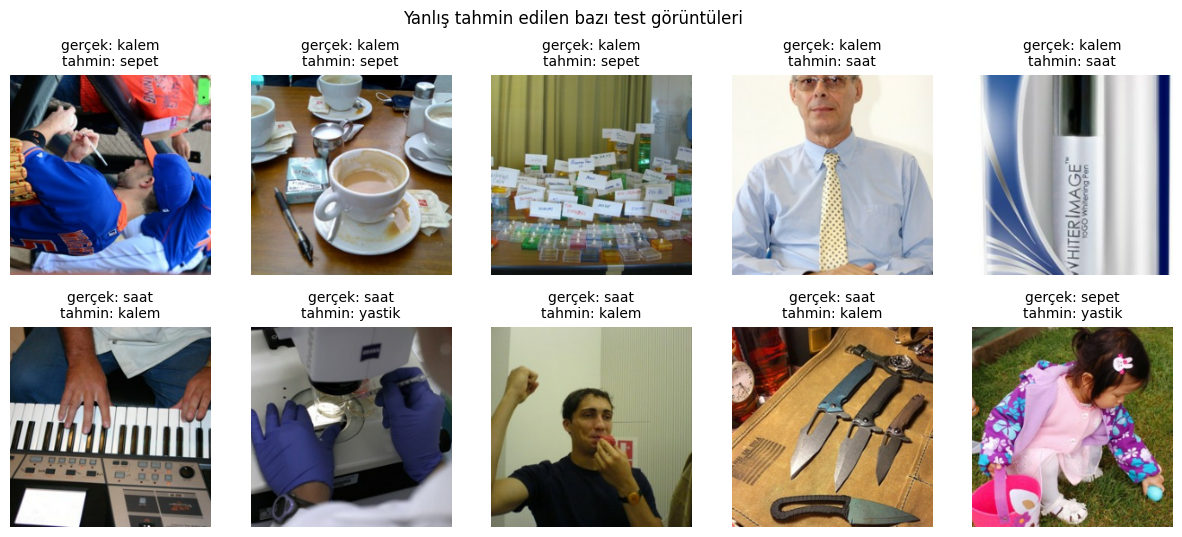

In [14]:
test_goruntuleri = np.concatenate([x.numpy() for x, _ in test_ds])
yanlislar = np.where(y_gercek != y_tahmin)[0][:10]

plt.figure(figsize=(15, 6))
for i, j in enumerate(yanlislar):
    plt.subplot(2, 5, i + 1)
    plt.imshow(test_goruntuleri[j].astype("uint8"))
    plt.title(f"gerçek: {sinif_adlari[y_gercek[j]]}\ntahmin: {sinif_adlari[y_tahmin[j]]}", fontsize=10)
    plt.axis("off")
plt.suptitle("Yanlış tahmin edilen bazı test görüntüleri")
plt.show()

## Kendi fotoğraflarım

Telefonumla çektiğim 5 fotoğrafı modele verdim. Dosya adı fotoğrafın gerçek sınıfı. Eğitimde `image_dataset_from_directory` görüntünün ortasından kare kestiği için kendi fotoğraflarımı da aynı şekilde ortadan kare kesip 224x224'e küçülttüm. Kalemin üzerinde adım yazdığı için o kısmı bulanıklaştırdım.

dosya       gerçek  tahmin   olasılık   2. tahmin
kalem.jpg   kalem   kalem       0.970   yastik (0.026)
saat.jpg    saat    saat        1.000   kalem (0.000)
sepet.jpg   sepet   sepet       0.747   yastik (0.212)
tavuk.jpg   tavuk   tavuk       0.982   yastik (0.014)
yastik.jpg  yastik  yastik      0.999   sepet (0.000)


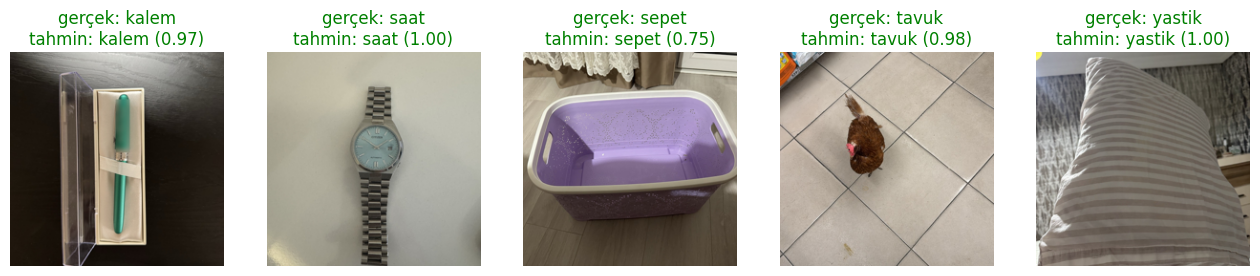

In [15]:
def hazirla(img):
    img = ImageOps.exif_transpose(img).convert("RGB")
    return np.array(ImageOps.fit(img, (BOYUT, BOYUT)), dtype="float32")

FOTO_KLASORU = "fotograflar"
dosyalar = sorted(f for f in os.listdir(FOTO_KLASORU) if f.lower().endswith(".jpg"))

plt.figure(figsize=(16, 4))
print(f"{'dosya':<12}{'gerçek':<8}{'tahmin':<8}{'olasılık':>9}   2. tahmin")
for i, dosya in enumerate(dosyalar):
    gercek = dosya.rsplit(".", 1)[0]
    x = hazirla(Image.open(os.path.join(FOTO_KLASORU, dosya)))
    p = model.predict(x[None], verbose=0)[0]
    sira = p.argsort()[::-1]
    tahmin = sinif_adlari[sira[0]]
    print(f"{dosya:<12}{gercek:<8}{tahmin:<8}{p[sira[0]]:>9.3f}   {sinif_adlari[sira[1]]} ({p[sira[1]]:.3f})")

    plt.subplot(1, len(dosyalar), i + 1)
    plt.imshow(x.astype("uint8"))
    plt.title(f"gerçek: {gercek}\ntahmin: {tahmin} ({p[sira[0]]:.2f})",
              color="green" if tahmin == gercek else "red")
    plt.axis("off")
plt.show()

## Değerlendirme

**Test seti.** Test accuracy 0.873, macro F1 0.859 çıktı. En iyi sınıflar tavuk (F1 0.937) ve yastık (0.912), en zayıfları kalem (0.800) ve saat (0.809). Bu iki sınıf aynı zamanda en az görüntüsü olan sınıflar (train'de 126 ve 108).

Confusion matrix'te en sık hata sepet → yastık (8 görüntü). Kalem ve saat de birbirine karışıyor. Yanlış tahmin edilen test görüntülerine bakınca hataların çoğunun veriden kaynaklandığını gördüm: Open Images'taki etiket "görüntünün bir yerinde kalem var" demek. Masada kahve fincanlarının arasında duran küçük bir kalem ya da birinin bileğindeki saat de bu sınıfa giriyor. Model böyle karelerde sahnede baskın olan şeye bakıyor. "Watch" etiketli bazı görüntülerde de aslında piyano veya bıçaklar ön planda. Yani nesne küçük olduğunda ya da etiket gürültülü olduğunda model zorlanıyor.

Eğitim eğrilerinde train accuracy 0.94'e çıkarken validation 0.87–0.89 arasında kaldı, biraz overfitting var. İnce ayar beklediğim kadar işe yaramadı: 1. aşamanın sonunda validation loss 0.311 idi, ince ayarda en iyi 0.319 oldu. Sınıf başına birkaç yüz görüntüyle son bloğu açmak fazla fayda sağlamadı.

**Kendi fotoğraflarım.** 5 fotoğrafın 5'ini de doğru tahmin etti:

| Fotoğraf | Gerçek | Tahmin | Olasılık | 2. tahmin |
|---|---|---|---|---|
| kalem.jpg | kalem | kalem | 0.970 | yastik (0.026) |
| saat.jpg | saat | saat | 1.000 | kalem (0.000) |
| sepet.jpg | sepet | sepet | 0.747 | yastik (0.212) |
| tavuk.jpg | tavuk | tavuk | 0.982 | yastik (0.014) |
| yastik.jpg | yastik | yastik | 0.999 | sepet (0.000) |

Başarılı olmasının sebebi bence fotoğraflarımda nesnenin kadrajın ortasında, büyük ve sade bir arka planın önünde olması. Test setindeki zor örneklerin tam tersi. Tavuk fotoğrafında tavuk küçük olmasına rağmen ortadan kare kesince kadrajda kaldı ve doğru bildi.

En zorlandığı fotoğraf sepet oldu (0.75). Open Images'taki sepet görüntülerinin çoğu hasır, örgü sepet; benimki mor plastik bir çamaşır sepeti. Model %21 ile yastık dedi, bu da test setinde en sık yaptığı sepet → yastık hatasıyla aynı. Kalem fotoğrafında kalem kumaş kaplı bir kutunun içinde olduğu için 2. tahmin yine yastık çıktı ama olasılığı çok düşük.

Başarısız olabileceği durumlar: 5 fotoğraf az bir test, hepsi doğru çıksa da test setindeki gibi nesnenin küçük olduğu ya da birden fazla nesnenin olduğu karelerde hata yapıyor. Ayrıca model sadece bu 5 sınıfı biliyor; başka bir nesnenin fotoğrafı verilirse yine bu 5 sınıftan birini söyleyecektir, çünkü softmax'ta "hiçbiri" seçeneği yok.

## Uygulama (Gradio)

Modeli Gradio ile bir web arayüzüne çevirdim. Kullanıcı bir fotoğraf yüklüyor, model 5 sınıfın olasılıklarını gösteriyor. Colab'da `share=True` ile geçici bir public link de veriyor. Örnek olarak kendi fotoğraflarımı ekledim.

In [16]:
import gradio as gr

def tahmin_et(img):
    p = model.predict(hazirla(img)[None], verbose=0)[0]
    return {s: float(p[i]) for i, s in enumerate(sinif_adlari)}

uygulama = gr.Interface(
    fn=tahmin_et,
    inputs=gr.Image(type="pil", label="Fotoğraf"),
    outputs=gr.Label(num_top_classes=5, label="Tahmin"),
    title="Kalem / Saat / Sepet / Tavuk / Yastık sınıflandırıcı",
    description="ResNet50 (transfer learning), Open Images V7 ile eğitildi.",
    examples=[os.path.join(FOTO_KLASORU, d) for d in dosyalar],
)
uygulama.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d21f6871f11bcbaa1b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Rapor

| Alan | Açıklama / Öğrenci yanıtı |
| :---- | :---- |
| Project Title | Kendi fotoğraflarımdaki 5 nesne için görüntü sınıflandırma (ResNet50 transfer learning) |
| Problem / Task | Görüntü sınıflandırma, 5 sınıf: kalem, saat, sepet, tavuk, yastık |
| Dataset | Open Images V7, insanlar tarafından doğrulanmış image-level etiketler (validation + test bölümleri). 1514 görüntü, %70 / %15 / %15 → 1059 / 227 / 228 |
| Dataset URL | https://storage.googleapis.com/openimages/web/index.html |
| Model Architecture | ResNet50 (ImageNet ağırlıkları, üst katman yok) + GlobalAveragePooling2D + Dropout(0.3) + Dense(5) |
| Input Size | 224 x 224 x 3 |
| Hyperparameters | Batch size 32. 1. aşama: ResNet50 donuk, lr 0.001, 10 epoch. 2. aşama: conv5 bloğu açık, lr 0.00001, en fazla 6 epoch (early stopping ile 5'te durdu). Dropout 0.3, early stopping patience 3, class weight, seed 33 |
| Optimizer | Adam |
| Activation / Output Function | ResNet50 içinde ReLU, çıkışta softmax |
| Loss Function | Categorical cross-entropy |
| Evaluation Metrics | Accuracy, Precision, Recall, F1-score (sınıf bazında ve macro), confusion matrix |
| Training Environment | Google Colab, NVIDIA T4 GPU, TensorFlow 2.21 / Keras 3. Eğitim süresi 131 sn (1. aşama 74 sn + 2. aşama 57 sn) |
| Best Performance | Test accuracy 0.873, macro F1 0.859. Kendi 5 fotoğrafım: 5/5 doğru |
| Inference Time | Toplu tahminde görüntü başına 28.3 ms, tek görüntü 228 ms (T4; tek görüntüde Keras'ın çağrı yükü baskın) |
| Deployment Technology | Gradio (Colab'da share=True ile public link) |
| Repository | https://github.com/Sqortle/DeepLearningComputerVision |